In [8]:
from qiskit import *    #### generate E0 and construct superpositions of E0 and E1
import numpy as np
from scipy.linalg import polar
from qiskit.circuit.library import UnitaryGate

from qiskit.quantum_info import Operator

U01AP=np.array([[0.499457,-0.1005,0.686603,0.49864],
             [-0.1005,0.989734,0.108495,0.0472221],
             [0.686603,0.108495,0.0117281,-0.719858],
             [0.49864,0.047221,-0.719858,0.499328]])
U01,_=polar(U01AP)   ##### unitarization by polar decomposition

print(U01)

#custom_gate=Operator(U01)

unitary_gate=UnitaryGate(U01,label="CustomGate")
controlled_gate=unitary_gate.control(1)

#[1]     ######  
n_site=2  ##### 
N=n_site 
j_coupling=1
a3=-0.0115
#a3=0
a0=0
a00=-1.04391
#a0=1
a2=-0.42045
#a2=0
J=0.42045 ########  
#J=0
a1=0.42045
a4=0.179005
#a4=2

step_max=288*3
t_max=36
dt=t_max/step_max


### simulator and Shots
simulator=Aer.get_backend('qasm_simulator')
n_shots=10000 #10^7

##### define quantum circuit
qr=QuantumRegister(14,'qr')
cr=ClassicalRegister(14,'cr')
qc=QuantumCircuit(qr, cr)

### measurement
qc_meas=QuantumCircuit(qr,cr)
qc_meas.measure(qr,cr)

### LIst
time_list_qiskit=[]
mag_list_qiskit=[]
magx_list_qiskit=[]
magy_list_qiskit=[]

##### Initial state

qc.x(qr[13]) 
#qc.x(qr[12])     ##########  Important

#qc.h(qr[13])
#qc.h(qr[12])

#################################   Z

  #  qc.h(qr[1])

#qc.draw('mpl')    
qc_total=qc.compose(qc_meas)

job=execute(qc_total, simulator, shots=n_shots)
result=job.result()
counts=result.get_counts(qc_total)
### print('Zmeasure', counts)

############################
mag00=0
for bit_string, count in counts.items():
    obs=0
    for j in range(n_site-1):   ### 2024-7-6 Changed n_site/ n_site-1                              
        obs=obs+1
        if j>=n_site-2:                                     
            mag00=mag00+a0*obs*count/n_shots
        else:
            mag00=mag00

print('mag00=',mag00)

#####################    
    
mag=0
for bit_string, count in counts.items():
    obs=0
    for j in range(n_site-1):                               
        obs=obs+(-1)**(int(bit_string[j]))  
        if j>=n_site-2:                    ##  j>=n_site-2:   
            mag=mag+a1*obs*count/n_shots/(1)
        else:
            mag=mag
#time_list_qiskit.append(dt*step)
#mag_list_qiskit.append(mag)
print('mag=',mag)
#print(bit_string[0])
#print(bit_string[1])
#print(bit_string[2])
#print(bit_string[3])
#################################
mag2=0
for bit_string, count in counts.items():
    obs=0
    for j in range(n_site-1):                               
        obs=obs+(-1)**(int(bit_string[j+1]))  
        if j>=n_site-2:                    ##  j>=n_site-2:   
            mag2=mag2+a2*obs*count/n_shots/(1)
        else:
            mag2=mag2
print('mag2=',mag2)

############################################  XX-energy
qc.h(qr[12])
qc.h(qr[13])
qc_total_xx=qc.compose(qc_meas)
  #  qc_total=qc+qc_meas  OLD
qc.h(qr[12])
qc.h(qr[13])
    

job=execute(qc_total_xx, simulator, shots=n_shots)
result=job.result()
counts=result.get_counts(qc_total_xx)
#print('xx-counts=', counts)
       
magx=0
obs=0
for bit_string, count in counts.items():
    for j in range(1):
        obs=obs+((-1)**((int(bit_string[0]))+(int(bit_string[1]))))*count
      #  print('obs=',obs)
    magx=a4*obs/n_shots
# time_list_qiskit.append(dt*step)
# magx_list_qiskit.append(magx)
print('magx=', magx)

#################################
    
qc_total_zz=qc.compose(qc_meas)
  #  qc_total=qc+qc_meas  OLD

    

job=execute(qc_total_zz, simulator, shots=n_shots)
result=job.result()
counts=result.get_counts(qc_total_zz)
       
magzz=0
obs=0
for bit_string, count in counts.items():
    for j in range(1):
        obs=obs+((-1)**((int(bit_string[0]))+(int(bit_string[1]))))*count
    magzz=a3*obs/n_shots
print('magzz=', magzz)

############################################  YY-energy
#########################################################################
print('EE=',mag00+magzz+mag+mag2+magx)
print('E0=', a00+magzz+mag+mag2+magx)

[[ 0.50997726 -0.07457948  0.69620855  0.49965463]
 [-0.0745792   0.98864935  0.10595974  0.07604568]
 [ 0.69620856  0.10596012  0.01084928 -0.70989323]
 [ 0.49965467  0.07604487 -0.70989329  0.49052412]]
mag00= 0.0
mag= -0.42045
mag2= -0.42045
magx= -0.000608617
magzz= 0.0115
EE= -0.830008617
E0= -1.8739186169999997


In [9]:
[2-1]  ### ABC  N=2 Improvement   ### Second-order Suzuki-Trotter formula 
##################################   the first group of the twirling operations
import numpy as np
E=-0.83
ss=0.5*np.pi/(E)
####ss=-0.5*np.pi/(np.sqrt(J**2+1))
Dt=0.01

qc.h(qr[10])
qc.h(qr[11])

#################################################
qc.s(qr[10])


for step1A in range(100):
    qc.p(-1*a0*ss*Dt,qr[10]) 
### JZ0                                                ######## 
    qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13])  ######## 
    qc.cx(qr[10],qr[13])
    qc.rz((-0.5*J*ss)*(step_max/step_max)*Dt,qr[13]) 
    qc.cx(qr[10],qr[13])
    qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13])

### Z1                                                ######## 
    qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12])  ######## 
    qc.cx(qr[10],qr[12])
    qc.rz((-0.5*a2*ss)*(step_max/step_max)*Dt,qr[12]) 
    qc.cx(qr[10],qr[12])
    qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12]) 
     
### ZZ
    qc.cx(qr[13],qr[12])    
    qc.rz((0.25*ss)*a3*Dt,qr[12]) 
    qc.cx(qr[10],qr[12])
    qc.rz((-0.5*ss)*a3*Dt,qr[12]) 
    qc.cx(qr[10],qr[12])
    qc.rz((0.25*ss)*a3*Dt,qr[12]) 
    qc.cx(qr[13],qr[12]) 
    
    
### XX
    qc.cx(qr[12],qr[13])    
    qc.rx((0.25*ss)*a4*Dt,qr[12]) 
    qc.cz(qr[10],qr[12])
    qc.rx((-0.5*ss)*a4*Dt,qr[12]) 
    qc.cz(qr[10],qr[12])
    qc.rx((0.25*ss)*a4*Dt,qr[12]) 
    qc.cx(qr[12],qr[13]) 
    
#### YY　
### XX
    qc.cx(qr[12],qr[13])    
    qc.rx((0.25*ss)*a4*Dt,qr[12]) 
    qc.cz(qr[10],qr[12])
    qc.rx((-0.5*ss)*a4*Dt,qr[12]) 
    qc.cz(qr[10],qr[12])
    qc.rx((0.25*ss)*a4*Dt,qr[12]) 
    qc.cx(qr[12],qr[13])    

### ZZ
    qc.cx(qr[13],qr[12])    
    qc.rz((0.25*ss)*a3*Dt,qr[12]) 
    qc.cx(qr[10],qr[12])
    qc.rz((-0.5*ss)*a3*Dt,qr[12]) 
    qc.cx(qr[10],qr[12])
    qc.rz((0.25*ss)*a3*Dt,qr[12]) 
    qc.cx(qr[13],qr[12]) 
    

### Z1                                                ######## 
    qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12])  ######## 
    qc.cx(qr[10],qr[12])
    qc.rz((-0.5*a2*ss)*(step_max/step_max)*Dt,qr[12]) 
    qc.cx(qr[10],qr[12])
    qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12]) 
    
### JZ                                                ######## 
    qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13])  
    qc.cx(qr[10],qr[13])
    qc.rz((-0.5*J*ss)*(step_max/step_max)*Dt,qr[13]) 
    qc.cx(qr[10],qr[13])
    qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13]) 
########################################################################### 
for stepBB in range (2):     ####  2023-4-27 LOOP1  2024-7-31 LOOP2
    qc.s(qr[11])
    
    for step1B in range(100):
        qc.p(-1*a0*ss*Dt,qr[11]) 

### JZ  
        qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13]) 
        qc.cx(qr[11],qr[13])
        qc.rz((-0.5*J*ss)*(step_max/step_max)*Dt,qr[13]) 
        qc.cx(qr[11],qr[13])
        qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13]) 
        
### Z1                                                ######## 2024-7-19
        qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12])  ######## 
        qc.cx(qr[11],qr[12])
        qc.rz((-0.5*a2*ss)*(step_max/step_max)*Dt,qr[12]) 
        qc.cx(qr[11],qr[12])
        qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12]) 

#### ZZ
        
        qc.cx(qr[13],qr[12])    
        qc.rz((0.25*ss)*a3*Dt,qr[12]) 
        qc.cx(qr[11],qr[12])
        qc.rz((-0.5*ss)*a3*Dt,qr[12]) 
        qc.cx(qr[11],qr[12])
        qc.rz((0.25*ss)*a3*Dt,qr[12])
        qc.cx(qr[13],qr[12]) 
        
### XX
        qc.cx(qr[12],qr[13])    
        qc.rx((0.25*ss)*a4*Dt,qr[12]) 
        qc.cz(qr[11],qr[12])
        qc.rx((-0.5*ss)*a4*Dt,qr[12]) 
        qc.cz(qr[11],qr[12])
        qc.rx((0.25*ss)*a4*Dt,qr[12])
        qc.cx(qr[12],qr[13]) 
        
#### YY　なし
### XX
        qc.cx(qr[12],qr[13])    
        qc.rx((0.25*ss)*a4*Dt,qr[12]) 
        qc.cz(qr[11],qr[12])
        qc.rx((-0.5*ss)*a4*Dt,qr[12]) 
        qc.cz(qr[11],qr[12])
        qc.rx((0.25*ss)*a4*Dt,qr[12])
        qc.cx(qr[12],qr[13]) 

### ZZ  
        
        qc.cx(qr[13],qr[12])    
        qc.rz((0.25*ss)*a3*Dt,qr[12]) 
        qc.cx(qr[11],qr[12])
        qc.rz((-0.5*ss)*a3*Dt,qr[12]) 
        qc.cx(qr[11],qr[12])
        qc.rz((0.25*ss)*a3*Dt,qr[12])
        qc.cx(qr[13],qr[12]) 
        
        
### Z1                                                ######## 2024-7-19
        qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12])  ######## 
        qc.cx(qr[11],qr[12])
        qc.rz((-0.5*a2*ss)*(step_max/step_max)*Dt,qr[12]) 
        qc.cx(qr[11],qr[12])
        qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12]) 

### JZ  
        qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13]) 
        qc.cx(qr[11],qr[13])
        qc.rz((-0.5*J*ss)*(step_max/step_max)*Dt,qr[13]) 
        qc.cx(qr[11],qr[13])
        qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13]) 
##########################################################################           

#################################################################
    
qc.h(qr[10])
qc.h(qr[11])

######################################### 
qc_total=qc.compose(qc_meas)

job=execute(qc_total, simulator, shots=n_shots)
result=job.result()
counts=result.get_counts(qc_total)


zero=0
for bit_string, count in counts.items():
    zero=zero+(1-int(bit_string[2]))*(1-int(bit_string[3]))*count 
print('zero=', zero)
   ### print('Z測定', counts)

###########################################################
mag00=0
for bit_string, count in counts.items():
    obs=0
    for j in range(n_site-1):   ### 2024-7-6 Changed n_site/ n_site-1                              
        obs=obs+1*(1-int(bit_string[2]))*(1-int(bit_string[3]))  
        if j>=n_site-2:                                     #### 2022-4-25  
            mag00=mag00+a0*obs*count/(zero)
        else:
            mag00=mag00

print('mag00=',mag00)
############################################################
    
mag=0
for bit_string, count in counts.items():
    obs=0
    for j in range(n_site-1):                               
        obs=obs+(-1)**(int(bit_string[j]))*(1-int(bit_string[2]))*(1-int(bit_string[3]))  
        if j>=n_site-2:                                     #### 2022-4-25  
            mag=mag+a1*obs*count/(zero)/(1)
        else:
            mag=mag
print('mag=',mag)
#######################################
mag2=0
for bit_string, count in counts.items():
    obs=0
    for j in range(n_site-1):                               
        obs=obs+(-1)**(int(bit_string[j+1]))*(1-int(bit_string[2]))*(1-int(bit_string[3]))  
        if j>=n_site-2:                                     #### 2022-4-25  
            mag2=mag2+a2*obs*count/(zero)/(1)
        else:
            mag2=mag2
print('mag2=',mag2)

############################################  XX-energy
    
qc.h(qr[12])
qc.h(qr[13])
qc_total_xx=qc.compose(qc_meas)
  #  qc_total=qc+qc_meas  OLD
qc.h(qr[12])
qc.h(qr[13])
    

job=execute(qc_total_xx, simulator, shots=n_shots)
result=job.result()
counts=result.get_counts(qc_total_xx)
#print('xx-counts=', counts)
       
magx=0
obs=0
obsy=0
for bit_string, count in counts.items():
    for j in range(1):
        obs=obs+((-1)**((int(bit_string[j]))+(int(bit_string[j+1]))))*(1-int(bit_string[2]))*(1-int(bit_string[3]))*count
        obsy=obsy+((-1)**((int(bit_string[0]))+(int(bit_string[1]))))*(1-int(bit_string[2]))*(1-int(bit_string[3]))*count
        #if j>=n_site-2:                                     #### 2022-4-25  
        #    magx=magx+a4*obs*count/(zero)/(1)
        #else:
    magx=a4*obs/(zero)/(1)
    magy=a4*obsy/(zero)/(1)
print('magx=', magx)
print('magy=', magy)
############################################## DUMMY
magxx=0
obsxx=0
for bit_string, count in counts.items():
    for j in range(1):
        obsxx=obsxx+((-1)**((int(bit_string[j]))+(int(bit_string[j+1]))))*(1-int(bit_string[2]))*(1-int(bit_string[3]))*count
                                          #### 
    magxx=a4*obsxx/(zero)/(1)
print('magxx=', magxx)
#################################
    
qc_total_zz=qc.compose(qc_meas)
  #  qc_total=qc+qc_meas  OLD
job=execute(qc_total_zz, simulator, shots=n_shots)
result=job.result()
counts=result.get_counts(qc_total_zz)
       
magzz=0
obs=0
for bit_string, count in counts.items():
    for j in range(1):
        obs=obs+((-1)**((int(bit_string[j]))+(int(bit_string[j+1]))))*(1-int(bit_string[2]))*(1-int(bit_string[3]))*count
    magzz=a3*obs/(zero)
print('magzz=', magzz)

############################################  YY-energy

print('EE=',mag00+ magzz+mag+mag2+magx)
print('E0=',a00+magzz+mag+mag2+magx)

zero= 9871
mag00= 0.0
mag= -0.4112495947725661
mag2= -0.4112495947725661
magx= -0.0388076891905582
magy= -0.0388076891905582
magxx= -0.0388076891905582
magzz= 0.0115
EE= -0.8498068787356905
E0= -1.8937168787356902


In [10]:
#[2-2]   the scond group of the twirling opeartion  
########################
import numpy as np
from functools import reduce
from operator import mul

E=-0.85
ss=0.5*np.pi/(E)
Dt=0.01

qc.h(qr[8])
qc.h(qr[9])

#################################################
qc.s(qr[8])


for step1A in range(100):
    qc.p(-1*a0*ss*Dt,qr[8]) 
### JZ                                                ######## 
    qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13])  ######## 
    qc.cx(qr[8],qr[13])
    qc.rz((-0.5*J*ss)*(step_max/step_max)*Dt,qr[13]) 
    qc.cx(qr[8],qr[13])
    qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13])

### Z1                                                ######## 
    qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12])  ######## 
    qc.cx(qr[8],qr[12])
    qc.rz((-0.5*a2*ss)*(step_max/step_max)*Dt,qr[12]) 
    qc.cx(qr[8],qr[12])
    qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12]) 
     
### ZZ
    
    qc.cx(qr[13],qr[12])    
    qc.rz((0.25*ss)*a3*Dt,qr[12]) 
    qc.cx(qr[8],qr[12])
    qc.rz((-0.5*ss)*a3*Dt,qr[12]) 
    qc.cx(qr[8],qr[12])
    qc.rz((0.25*ss)*a3*Dt,qr[12]) 
    qc.cx(qr[13],qr[12]) 

    
### XX
    qc.cx(qr[12],qr[13])    
    qc.rx((0.25*ss)*a4*Dt,qr[12]) 
    qc.cz(qr[8],qr[12])
    qc.rx((-0.5*ss)*a4*Dt,qr[12]) 
    qc.cz(qr[8],qr[12])
    qc.rx((0.25*ss)*a4*Dt,qr[12]) 
    qc.cx(qr[12],qr[13]) 

### XX
    qc.cx(qr[12],qr[13])    
    qc.rx((0.25*ss)*a4*Dt,qr[12]) 
    qc.cz(qr[8],qr[12])
    qc.rx((-0.5*ss)*a4*Dt,qr[12]) 
    qc.cz(qr[8],qr[12])
    qc.rx((0.25*ss)*a4*Dt,qr[12]) 
    qc.cx(qr[12],qr[13]) 
    
### ZZ
    
    qc.cx(qr[13],qr[12])    
    qc.rz((0.25*ss)*a3*Dt,qr[12]) 
    qc.cx(qr[8],qr[12])
    qc.rz((-0.5*ss)*a3*Dt,qr[12]) 
    qc.cx(qr[8],qr[12])
    qc.rz((0.25*ss)*a3*Dt,qr[12]) 
    qc.cx(qr[13],qr[12]) 
    

### Z1                                                ######## 
    qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12])  ######## 
    qc.cx(qr[8],qr[12])
    qc.rz((-0.5*a2*ss)*(step_max/step_max)*Dt,qr[12]) 
    qc.cx(qr[8],qr[12])
    qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12]) 
     
    
### JZ                                                ######## 
    qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13])  
    qc.cx(qr[8],qr[13])
    qc.rz((-0.5*J*ss)*(step_max/step_max)*Dt,qr[13]) 
    qc.cx(qr[8],qr[13])
    qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13]) 
########################################################################### 
for stepBB in range (2):    #### 2024-7-1 LOOP2
    qc.s(qr[9])
    

    for step1B in range(100):
        qc.p(-1*a0*ss*Dt,qr[9]) 
### JZ  
        qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13]) 
        qc.cx(qr[9],qr[13])
        qc.rz((-0.5*J*ss)*(step_max/step_max)*Dt,qr[13]) 
        qc.cx(qr[9],qr[13])
        qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13]) 

### Z1                                                ########
        qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12])  ######## 
        qc.cx(qr[9],qr[12])
        qc.rz((-0.5*a2*ss)*(step_max/step_max)*Dt,qr[12]) 
        qc.cx(qr[9],qr[12])
        qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12]) 

### ZZ
        
        qc.cx(qr[13],qr[12])    
        qc.rz((0.25*ss)*a3*Dt,qr[12]) 
        qc.cx(qr[9],qr[12])
        qc.rz((-0.5*ss)*a3*Dt,qr[12]) 
        qc.cx(qr[9],qr[12])
        qc.rz((0.25*ss)*a3*Dt,qr[12])
        qc.cx(qr[13],qr[12]) 
        

### XX
        qc.cx(qr[12],qr[13])    
        qc.rx((0.25*ss)*a4*Dt,qr[12]) 
        qc.cz(qr[9],qr[12])
        qc.rx((-0.5*ss)*a4*Dt,qr[12]) 
        qc.cz(qr[9],qr[12])
        qc.rx((0.25*ss)*a4*Dt,qr[12])
        qc.cx(qr[12],qr[13]) 
    
    
#### YY nashi
### XX
        qc.cx(qr[12],qr[13])    
        qc.rx((0.25*ss)*a4*Dt,qr[12]) 
        qc.cz(qr[9],qr[12])
        qc.rx((-0.5*ss)*a4*Dt,qr[12]) 
        qc.cz(qr[9],qr[12])
        qc.rx((0.25*ss)*a4*Dt,qr[12])
        qc.cx(qr[12],qr[13]) 
    

### ZZ
        
        qc.cx(qr[13],qr[12])    
        qc.rz((0.25*ss)*a3*Dt,qr[12]) 
        qc.cx(qr[9],qr[12])
        qc.rz((-0.5*ss)*a3*Dt,qr[12]) 
        qc.cx(qr[9],qr[12])
        qc.rz((0.25*ss)*a3*Dt,qr[12])
        qc.cx(qr[13],qr[12]) 
        

### Z1                                                ######## 
        qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12])  ######## 
        qc.cx(qr[9],qr[12])
        qc.rz((-0.5*a2*ss)*(step_max/step_max)*Dt,qr[12]) 
        qc.cx(qr[9],qr[12])
        qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12]) 


### JZ  
        qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13]) 
        qc.cx(qr[9],qr[13])
        qc.rz((-0.5*J*ss)*(step_max/step_max)*Dt,qr[13]) 
        qc.cx(qr[9],qr[13])
        qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13]) 
##########################################################################           

#################################################################
    
qc.h(qr[8])
qc.h(qr[9])

######################################### 
qc_total=qc.compose(qc_meas)

job=execute(qc_total, simulator, shots=n_shots)
result=job.result()
counts=result.get_counts(qc_total)

zero=0
for bit_string, count in counts.items():
    zero=zero+(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5]))*count 
print('zero=', zero)
##########################################
mag00=0
for bit_string, count in counts.items():
    obs=0
    for j in range(n_site-1):   ### 2024-7-6 Changed n_site/ n_site-1                              
        obs=obs+1*(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5]))
        if j>=n_site-2:                                     #### 
            mag00=mag00+a0*obs*count/(zero)
        else:
            mag00=mag00

print('mag00=',mag00)
######################################################
    
mag=0
for bit_string, count in counts.items():
    obs=0
    for j in range(n_site-1):                               
        obs=obs+(-1)**(int(bit_string[j]))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,5)))))    #  *(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5])) 
        if j>=n_site-2:                                     #### 
            mag=mag+a1*obs*count/(zero)/(1)
        else:
            mag=mag
print('mag=',mag)

######################################################
mag2=0
for bit_string, count in counts.items():
    obs=0
    for j in range(n_site-1):                               
        obs=obs+(-1)**(int(bit_string[j+1]))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,5)))))    #  *(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5])) 
        if j>=n_site-2:                                     #### 
            mag2=mag2+a2*obs*count/(zero)/(1)
        else:
            mag2=mag2
print('mag2=',mag2)

############################################  XX-energy
qc.h(qr[12])
qc.h(qr[13])
qc_total_xx=qc.compose(qc_meas)
  #  qc_total=qc+qc_meas  OLD
qc.h(qr[12])
qc.h(qr[13])
    

job=execute(qc_total_xx, simulator, shots=n_shots)
result=job.result()
counts=result.get_counts(qc_total_xx)
       
magx=0
obs=0
for bit_string, count in counts.items():
    for j in range(1):
        obs=obs+((-1)**((int(bit_string[j]))+(int(bit_string[j+1]))))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,5)))))*count #*(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5]))*count
       # print('obs=',obs)
        magx=a4*obs/(zero)
print('magx=', magx)

#################################
qc_total_zz=qc.compose(qc_meas)

job=execute(qc_total_zz, simulator, shots=n_shots)
result=job.result()
counts=result.get_counts(qc_total_zz)
       
magzz=0
obs=0
for bit_string, count in counts.items():
    for j in range(1):
        obs=obs+((-1)**((int(bit_string[j]))+(int(bit_string[j+1]))))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,5)))))*count #*(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5]))*count
    magzz=a3*obs/(zero)
print('magzz=', magzz)

############################################  YY
print('EE=', mag00+magzz+mag+mag2+magx)
print('E0=', a00+magzz+mag+mag2+magx)

zero= 9864
mag00= 0.0
mag= -0.41149881386861314
mag2= -0.41149881386861314
magx= -0.037673801703163014
magzz= 0.011517487834549877
EE= -0.8491539416058395
E0= -1.8930639416058392


In [11]:
#[2-3]  ### the third group of the twirling operation 
##################################   
import numpy as np
from functools import reduce
from operator import mul

E=-0.849
ss=0.5*np.pi/(E)
Dt=0.01

qc.h(qr[6])
qc.h(qr[7])

#################################################
qc.s(qr[6])


for step1A in range(100):
    qc.p(-1*a0*ss*Dt,qr[6]) 
### JZ                                                ######## 
    qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13])  ######## 
    qc.cx(qr[6],qr[13])
    qc.rz((-0.5*J*ss)*(step_max/step_max)*Dt,qr[13]) 
    qc.cx(qr[6],qr[13])
    qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13])
    
### Z1                                               ######## 
    qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12])  ######## 
    qc.cx(qr[6],qr[12])
    qc.rz((-0.5*a2*ss)*(step_max/step_max)*Dt,qr[12]) 
    qc.cx(qr[6],qr[12])
    qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12]) 
     
### ZZ

    qc.cx(qr[13],qr[12])    
    qc.rz((0.25*ss)*a3*Dt,qr[12]) 
    qc.cx(qr[6],qr[12])
    qc.rz((-0.5*ss)*a3*Dt,qr[12]) 
    qc.cx(qr[6],qr[12])
    qc.rz((0.25*ss)*a3*Dt,qr[12]) 
    qc.cx(qr[13],qr[12])
    
    
### XX
    qc.cx(qr[12],qr[13])    
    qc.rx((0.25*ss)*a4*Dt,qr[12]) 
    qc.cz(qr[6],qr[12])
    qc.rx((-0.5*ss)*a4*Dt,qr[12]) 
    qc.cz(qr[6],qr[12])
    qc.rx((0.25*ss)*a4*Dt,qr[12]) 
    qc.cx(qr[12],qr[13]) 
    
    
#### YY nashi

### XX
    qc.cx(qr[12],qr[13])    
    qc.rx((0.25*ss)*a4*Dt,qr[12]) 
    qc.cz(qr[6],qr[12])
    qc.rx((-0.5*ss)*a4*Dt,qr[12]) 
    qc.cz(qr[6],qr[12])
    qc.rx((0.25*ss)*a4*Dt,qr[12]) 
    qc.cx(qr[12],qr[13]) 
    

### ZZ
    
    qc.cx(qr[13],qr[12])    
    qc.rz((0.25*ss)*a3*Dt,qr[12]) 
    qc.cx(qr[6],qr[12])
    qc.rz((-0.5*ss)*a3*Dt,qr[12]) 
    qc.cx(qr[6],qr[12])
    qc.rz((0.25*ss)*a3*Dt,qr[12]) 
    qc.cx(qr[13],qr[12]) 
    
### Z1                                               ######## 
    qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12])  ######## 
    qc.cx(qr[6],qr[12])
    qc.rz((-0.5*a2*ss)*(step_max/step_max)*Dt,qr[12]) 
    qc.cx(qr[6],qr[12])
    qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12]) 
     
    
### JZ                                                ######## 
    qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13])  
    qc.cx(qr[6],qr[13])
    qc.rz((-0.5*J*ss)*(step_max/step_max)*Dt,qr[13]) 
    qc.cx(qr[6],qr[13])
    qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13]) 
########################################################################### 
for stepBB in range (2): #####  Two-LOOP
    qc.s(qr[7])
     

    for step1B in range(100):
        qc.p(-1*a0*ss*Dt,qr[7])
### JZ  
        qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13]) 
        qc.cx(qr[7],qr[13])
        qc.rz((-0.5*J*ss)*(step_max/step_max)*Dt,qr[13]) 
        qc.cx(qr[7],qr[13])
        qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13]) 

### Z1                                               ######## 
        qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12])  ######## 
        qc.cx(qr[7],qr[12])
        qc.rz((-0.5*a2*ss)*(step_max/step_max)*Dt,qr[12]) 
        qc.cx(qr[7],qr[12])
        qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12]) 

### ZZ
        
        qc.cx(qr[13],qr[12])    
        qc.rz((0.25*ss)*a3*Dt,qr[12]) 
        qc.cx(qr[7],qr[12])
        qc.rz((-0.5*ss)*a3*Dt,qr[12]) 
        qc.cx(qr[7],qr[12])
        qc.rz((0.25*ss)*a3*Dt,qr[12])
        qc.cx(qr[13],qr[12]) 
        
### XX
        qc.cx(qr[12],qr[13])    
        qc.rx((0.25*ss)*a4*Dt,qr[12]) 
        qc.cz(qr[7],qr[12])
        qc.rx((-0.5*ss)*a4*Dt,qr[12]) 
        qc.cz(qr[7],qr[12])
        qc.rx((0.25*ss)*a4*Dt,qr[12])
        qc.cx(qr[12],qr[13]) 
    
        
#### YY nashi

### XX
        qc.cx(qr[12],qr[13])    
        qc.rx((0.25*ss)*a4*Dt,qr[12]) 
        qc.cz(qr[7],qr[12])
        qc.rx((-0.5*ss)*a4*Dt,qr[12]) 
        qc.cz(qr[7],qr[12])
        qc.rx((0.25*ss)*a4*Dt,qr[12])
        qc.cx(qr[12],qr[13]) 
    

### ZZ
        qc.cx(qr[13],qr[12])    
        qc.rz((0.25*ss)*a3*Dt,qr[12]) 
        qc.cx(qr[7],qr[12])
        qc.rz((-0.5*ss)*a3*Dt,qr[12]) 
        qc.cx(qr[7],qr[12])
        qc.rz((0.25*ss)*a3*Dt,qr[12])
        qc.cx(qr[13],qr[12])
        
### Z1                                               ######## 
        qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12])  ######## 
        qc.cx(qr[7],qr[12])
        qc.rz((-0.5*a2*ss)*(step_max/step_max)*Dt,qr[12]) 
        qc.cx(qr[7],qr[12])
        qc.rz((0.25*a2*ss)*(step_max/step_max)*Dt,qr[12]) 

### JZ  
        qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13]) 
        qc.cx(qr[7],qr[13])
        qc.rz((-0.5*J*ss)*(step_max/step_max)*Dt,qr[13]) 
        qc.cx(qr[7],qr[13])
        qc.rz((0.25*J*ss)*(step_max/step_max)*Dt,qr[13]) 
##########################################################################           
#################################################################
    
qc.h(qr[6])
qc.h(qr[7])

######################################### 2023-1-2
qc_total=qc.compose(qc_meas)

job=execute(qc_total, simulator, shots=n_shots)
result=job.result()
counts=result.get_counts(qc_total)

zero=0
for bit_string, count in counts.items():
    zero=zero+((reduce(mul,((1-int(bit_string[i])) for i in range(2,7))))) *count 
print('zero=', zero)
   ### print('Z測定', counts)

###########################################
mag00=0
for bit_string, count in counts.items():
    obs=0
    for j in range(n_site-1):   ### 2024-7-6 Changed n_site/ n_site-1                              
        obs=obs+1*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))
        if j>=n_site-2:                                     #### 
            mag00=mag00+a0*obs*count/(zero)
        else:
            mag00=mag00

print('mag00=',mag00)
#############################################
    
mag=0
for bit_string, count in counts.items():
    obs=0
    for j in range(n_site-1):                               
        obs=obs+(-1)**(int(bit_string[j]))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))    #  *(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5])) 
        if j>=n_site-2:                                     #### 
            mag=mag+a1*obs*count/(zero)/(1)
        else:
            mag=mag
print('mag=',mag)

#############################################
    
mag2=0
for bit_string, count in counts.items():
    obs=0
    for j in range(n_site-1):                               
        obs=obs+(-1)**(int(bit_string[j+1]))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))    #  *(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5])) 
        if j>=n_site-2:                                     #### 
            mag2=mag2+a2*obs*count/(zero)/(1)
        else:
            mag2=mag2
print('mag2=',mag2)

############################################  XX-energy
qc.h(qr[12])
qc.h(qr[13])
qc_total_xx=qc.compose(qc_meas)
  #  qc_total=qc+qc_meas  OLD
qc.h(qr[12])
qc.h(qr[13])
    

job=execute(qc_total_xx, simulator, shots=n_shots)
result=job.result()
counts=result.get_counts(qc_total_xx)
       
magx=0
obs=0
for bit_string, count in counts.items():
    for j in range(1):
        obs=obs+((-1)**((int(bit_string[0]))+(int(bit_string[1]))))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*count #*(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5]))*count
    magx=a4*obs/(zero)
print('magx=', magx)

#################################
    
qc_total_zz=qc.compose(qc_meas)
  #  qc_total=qc+qc_meas  OLD
    
job=execute(qc_total_zz, simulator, shots=n_shots)
result=job.result()
counts=result.get_counts(qc_total_zz)
       
magzz=0
obs=0
for bit_string, count in counts.items():
    for j in range(1):
        obs=obs+((-1)**((int(bit_string[0]))+(int(bit_string[1]))))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*count #*(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5]))*count
    magzz=a3*obs/(zero)
print('magzz=', magzz)

############################################  YY-energy
print('EE=', mag00+magzz+mag+mag2+magx)
print('E0=', a00+magzz+mag+mag2+magx)

zero= 9894
mag00= 0.0
mag= -0.41093101879927235
mag2= -0.41093101879927235
magx= -0.038500367899737216
magzz= 0.011482565191024863
EE= -0.848879840307257
E0= -1.892789840307257


In [12]:
#   
#[3]   construct superpositions
##################################   
import numpy as np
from functools import reduce
from operator import mul

#  unitary transformation
#qc.unitary(custom_gate,[12,13],label="CustomGate")
qc.h(qr[5])  ###  5: controle qubits
#qc.s(qr[5]) ###  s(i) in Fig.3   E0 \pm iE1
qc.append(controlled_gate,[5,12,13])   #### 12,13 physical qubits
qc.h(qr[5])
######################################### 
qc_total=qc.compose(qc_meas)

job=execute(qc_total, simulator, shots=n_shots)
result=job.result()
counts=result.get_counts(qc_total)

zero=0
ichi=0
for bit_string, count in counts.items():
    zero=zero+((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(1-int(bit_string[8])) *count
    ichi=ichi+((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(int(bit_string[8])) *count
    
print('zero=', zero)
print('ichi=', ichi)

###########################################
mag00=0
for bit_string, count in counts.items():
    obs=0
    for j in range(n_site-1):   ### 2024-7-6 Changed n_site/ n_site-1                              
        obs=obs+1*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(1-int(bit_string[8]))
        if j>=n_site-2:                                     #### 
            mag00=mag00+a00*obs*count/(zero)  ### a0 --a00
        else:
            mag00=mag00

print('mag00=',mag00)
print('###############################')
#############################################
    
mag0=0
mag1=0
for bit_string, count in counts.items():
    obs0=0
    obs1=0
    for j in range(n_site-1):                               
        obs0=obs0+(-1)**(int(bit_string[j]))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(1-int(bit_string[8]))    #  *(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5])) 
        obs1=obs1+(-1)**(int(bit_string[j]))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(int(bit_string[8]))    #  *(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5])) 
        if j>=n_site-2:                                     #### 
            mag0=mag0+1*obs0*count/(zero)/(1)
            mag1=mag1+1*obs1*count/(ichi)/(1)
        else:
            mag0=mag0
            mag1=mag1
print('mag0=',mag0)
print('mag1=',mag1)
print('mag0-mag1=',mag0-mag1)
print('############################')

#############################################
    
mag20=0
mag21=0
for bit_string, count in counts.items():
    obs0=0
    obs1=0
    for j in range(n_site-1):                               
        obs0=obs0+(-1)**(int(bit_string[j+1]))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(1-int(bit_string[8]))    #  *(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5])) 
        obs1=obs1+(-1)**(int(bit_string[j+1]))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(int(bit_string[8]))    #  *(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5])) 
        if j>=n_site-2:                                     #### 
            mag20=mag20+1*obs0*count/(zero)/(1)
            mag21=mag21+1*obs1*count/(ichi)/(1)
        else:
            mag20=mag20
            mag21=mag21
print('mag20=',mag20)
print('mag21=',mag21)
print('mag20-mag21=', mag20-mag21)
print('#######################################')

############################################  XX
qc.h(qr[12])
qc.h(qr[13])
qc_total_xx=qc.compose(qc_meas)
  #  qc_total=qc+qc_meas  OLD
qc.h(qr[12])
qc.h(qr[13])
    

job=execute(qc_total_xx, simulator, shots=n_shots)
result=job.result()
counts=result.get_counts(qc_total_xx)
       
magxx0=0
magxx1=0
obs0=0
obs1=0
for bit_string, count in counts.items():
    for j in range(1):
        obs0=obs0+((-1)**((int(bit_string[0]))+(int(bit_string[1]))))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(1-int(bit_string[8]))*count #*(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5]))*count
        obs1=obs1+((-1)**((int(bit_string[0]))+(int(bit_string[1]))))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(int(bit_string[8]))*count #*(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5]))*count
       # print('obs=',obs)       
    magxx0=1*obs0/(zero)
    magxx1=obs1/(ichi)
# time_list_qiskit.append(dt*step)
#magx_list_qiskit.append(magx)
print('magxx0=', magxx0)
print('magxx1=', magxx1)
print('magxx0-magxx1=', magxx0-magxx1)
print('################################')
#################################################### XI
qc.h(qr[13])
qc_total=qc.compose(qc_meas)
  #  qc_total=qc+qc_meas  OLD
qc.h(qr[13])
    

job=execute(qc_total, simulator, shots=n_shots)
result=job.result()
counts=result.get_counts(qc_total)
       
magxI0=0
magXI1=0
obs0=0
obs1=0
for bit_string, count in counts.items():
    for j in range(1):
        obs0=obs0+((-1)**((int(bit_string[0]))))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(1-int(bit_string[8]))*count #*(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5]))*count
        obs1=obs1+((-1)**((int(bit_string[0]))))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(int(bit_string[8]))*count #*(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5]))*count
    magxI0=1*obs0/(zero)
    magxI1=obs1/(ichi)
print('magxI0=', magxI0)
print('magxI1=', magxI1)
print('magxI0-magxI1=', magxI0-magxI1)
print('################################')
#################################
    
qc_total_zz=qc.compose(qc_meas)
  #  qc_total=qc+qc_meas  OLD
    
job=execute(qc_total_zz, simulator, shots=n_shots)
result=job.result()
counts=result.get_counts(qc_total_zz)
       
magzz0=0
magzz=0
obs0=0
obs1=0
for bit_string, count in counts.items():
    for j in range(1):
        obs0=obs0+((-1)**((int(bit_string[0]))+(int(bit_string[1]))))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(1-int(bit_string[8]))*count #*(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5]))*count
        obs1=obs1+((-1)**((int(bit_string[0]))+(int(bit_string[1]))))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(int(bit_string[8]))*count #*(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5]))*count   
    magzz0=1*obs0/(zero)
    magzz1=1*obs0/(ichi)
print('magzz0=', magzz0)
print('magzz1=', magzz1)
print('magzz0-magzz1=', magzz0-magzz1)
print('#######################################')
############################################  YY-energy
qc.rx(0.5*np.pi,qr[12])
qc.rx(0.5*np.pi,qr[13])
qc_total=qc.compose(qc_meas)
  #  qc_total=qc+qc_meas  OLD
qc.rx(-0.5*np.pi,qr[12])
qc.rx(-0.5*np.pi,qr[13])

job=execute(qc_total, simulator, shots=n_shots)
result=job.result()
counts=result.get_counts(qc_total)
       
magyy0=0
magyy1=0
obs0=0
obs1=0
for bit_string, count in counts.items():
    for j in range(1):
        obs0=obs0+((-1)**((int(bit_string[0]))+(int(bit_string[1]))))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(1-int(bit_string[8]))*count #*(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5]))*count
        obs1=obs1+((-1)**((int(bit_string[0]))+(int(bit_string[1]))))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(int(bit_string[8]))*count #*(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5]))*count
    magyy0=1*obs0/(zero)
    magyy1=obs1/(ichi)
print('magyy0=', magyy0)
print('magyy1=', magyy1)
print('magyy0-magyy1=', magyy0-magyy1)
print('#################################')
##################################################################### YI
qc.rx(0.5*np.pi,qr[13])
qc_total=qc.compose(qc_meas)
  #  qc_total=qc+qc_meas  OLD
qc.rx(-0.5*np.pi,qr[13])

job=execute(qc_total, simulator, shots=n_shots)
result=job.result()
counts=result.get_counts(qc_total)
       
magyI0=0
magyI1=0
obs0=0
obs1=0
for bit_string, count in counts.items():
    for j in range(1):
        obs0=obs0+((-1)**(int(bit_string[0])))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(1-int(bit_string[8]))*count #*(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5]))*count
        obs1=obs1+((-1)**(int(bit_string[0])))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(int(bit_string[8]))*count #*(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5]))*count
    magyI0=1*obs0/(zero)
    magyI1=obs1/(ichi)
print('magyI0=', magyI0)
print('magyI1=', magyI1)
print('magyI0-magyI1=', magyI0-magyI1)
print('#################################')

print('0.5(E0+E1)=', mag00+a3*magzz0+a1*mag0+a2*mag20+a4*magxx0)

zero= 4947
ichi= 4928
mag00= -1.04391
###############################
mag0= -0.49868607236709117
mag1= -0.4983766233766234
mag0-mag1= -0.0003094489904677533
############################
mag20= 0.49343036183545586
mag21= 0.46753246753246763
mag20-mag21= 0.025897894302988222
#######################################
magxx0= -0.5839902971497878
magxx1= -0.6162743506493507
magxx0-magxx1= 0.03228405349956287
################################
magxI0= 0.7626844552253891
magxI1= -0.7745535714285714
magxI0-magxI1= 1.5372380266539605
################################
magzz0= 0.025672124519911056
magzz1= 0.025771103896103896
magzz0-magzz1= -9.897937619283981e-05
#######################################
magyy0= 0.39357186173438446
magyy1= 0.40645292207792205
magyy0-magyy1= -0.012881060343537587
#################################
magyI0= 0.009500707499494642
magyI1= -0.008522727272727272
magyI0-magyI1= 0.018023434772221916
#################################
0.5(E0+E1)= -1.5658777673337374


In [13]:
### time evolution  2025-11-25
Dt=0.1       #### 2025-11-25

for step1A in range(1000):
###    qc.p(-1*a0*ss*Dt,qr[6])                          #####  2025-11-25
### JZ(Z0)                                                
    qc.rz((1*J)*(step_max/step_max)*Dt,qr[13])  
    
### Z1                                               
    qc.rz((1*a2)*(step_max/step_max)*Dt,qr[12])  
     
### ZZ

    qc.cx(qr[13],qr[12])    
    qc.rz(1*a3*Dt,qr[12]) 
    qc.cx(qr[13],qr[12])
    
    
### XX
    qc.cx(qr[12],qr[13])    
    qc.rx(1*a4*Dt,qr[12]) 
    qc.cx(qr[12],qr[13]) 
    
    
####N0-YY 

### XX
    qc.cx(qr[12],qr[13])    
    qc.rx(1*a4*Dt,qr[12]) 
    qc.cx(qr[12],qr[13]) 
    

### ZZ
    
    qc.cx(qr[13],qr[12])    
    qc.rz(1*a3*Dt,qr[12]) 
    qc.cx(qr[13],qr[12]) 
    
### Z1                                               
    qc.rz((1*a2)*(step_max/step_max)*Dt,qr[12])  
     
### JZ (Z0)                                               
    qc.rz((1*J)*(step_max/step_max)*Dt,qr[13])  

################################################################## 2025-11-27 XI
    qc.h(qr[13])
    qc_total=qc.compose(qc_meas)
    qc.h(qr[13])

    job=execute(qc_total, simulator, shots=n_shots)
    result=job.result()
    counts=result.get_counts(qc_total)

    zero=0
    ichi=0
    for bit_string, count in counts.items():
        zero=zero+((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(1-int(bit_string[8])) *count
        ichi=ichi+((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(int(bit_string[8])) *count
    
    #print('zero=', zero)
    #print('ichi=', ichi)
   ### print('Z測定', counts)
############################################# 2025-11-27
    magx0=0
    magx1=0
    for bit_string, count in counts.items():
        obs0=0
        obs1=0
        for j in range(n_site-1):                               
            obs0=obs0+(-1)**(int(bit_string[j]))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(1-int(bit_string[8]))    #  *(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5])) 
            obs1=obs1+(-1)**(int(bit_string[j]))*((reduce(mul,((1-int(bit_string[i])) for i in range(2,7)))))*(int(bit_string[8]))    #  *(1-int(bit_string[2]))*(1-int(bit_string[3]))*(1-int(bit_string[4]))*(1-int(bit_string[5])) 
            if j>=n_site-2:                                     #### 2022-4-25  koko-tyuui   １回のみ加える
                magx0=magx0+1*obs0*count/(zero)/(1)
                magx1=magx1+1*obs1*count/(ichi)/(1)
            else:
                magx0=magx0
                magx1=magx1
#time_list_qiskit.append(dt*step)
#print('mag1=',mag1)
    #print('mag0-mag1=',mag0-mag1)
    time_list_qiskit.append(Dt*step1A)
    mag_list_qiskit.append(magx0)
#    print('magx0=',magx0)

print('zero=',zero)
print('ichi',ichi)
print('XI=',magx0)
print('############################')



zero= 4917
ichi 4955
XI= -0.7722188326215172
############################


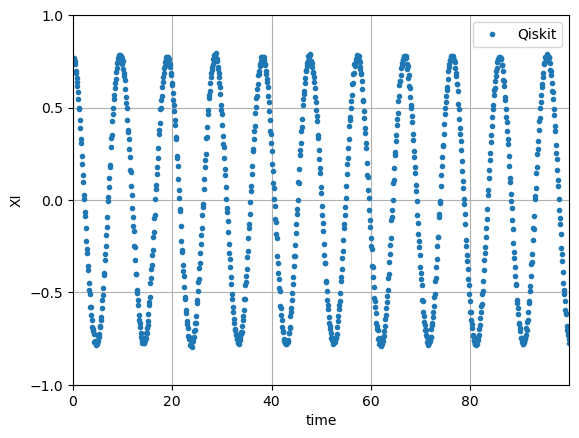

In [17]:
import matplotlib.pyplot as plt
import numpy as np

#  H2-molecule
x = np.linspace(0, 36, 100)
fig, ax = plt.subplots()

# y
ax.set_yticks([-1, -0.5, 0, 0.5, 1])
ax.set_ylim(-1, 1)  

# x
ax.set_xlim(min(time_list_qiskit), max(time_list_qiskit))

# data plot
plt.plot(time_list_qiskit, mag_list_qiskit, ".", label='Qiskit')
plt.xlabel('time')
plt.ylabel('XI')
plt.legend()
plt.grid(True)  

#plt.savefig("my_plot.png")   





